# Prefill on consumer cards: structure, not tuning

A decision model reads a long document once (a *state*, about 28k tokens) and then answers several short questions
over it. Only prefill runs. On an RTX 3090 the large matrix multiplies already run at about 95% of the card's bf16
peak, so a change has to remove work, share work or make a fused kernel legal. A measured change counts only when
its paired interval clears a margin set from this card's own A/A runs, and its answers pass the drift gate:

$$
\text{adopt} \iff \text{CI}_{90}^{\text{lo}}(\hat\rho) > m \ \text{ and numerics pass}, \qquad m \ge 2 \max |\hat\rho_{A/A} - 1| .
$$

**Evidence:** recorded RTX 3090 run summaries (paired ratios, intervals, drift) and profile shares, replayed on CPU.
The model, its serving harness and the GPU runs are not distributed here.
[Writeup](../docs/writeups/WRITEUP_SM86_SM89.md) · [measurement contract](../docs/getting-started.md#measurement).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "xcalibur").is_dir():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import xcalibur as xc
from style import C, SEQ, MUTED, INK, DATA, save, note
runs = pd.read_csv(DATA / "kev_prefill_runs.csv")
aa = runs[runs.label.str.startswith("K1")]
worst = (aa.median_ratio - 1).abs().max()
print("worst A/A offset: %.4f  ->  margin >= %.4f" % (worst, 2 * worst))
meas = runs[runs.ci90_lo.notna() & ~runs.label.str.startswith("K1")].copy()
meas["speed_clears_margin"] = meas.ci90_lo > meas.margin
meas[["label", "change", "median_ratio", "ci90_lo", "ci90_hi", "margin", "speed_clears_margin", "decision"]]

worst A/A offset: 0.0008  ->  margin >= 0.0016


,label,change,median_ratio,ci90_lo,ci90_hi,margin,speed_clears_margin,decision
2,K2,fused vs unfused (KEV_FUSED=1 vs 0),1.1398,1.1380,1.1402,1.003,True,baseline (reference drift)
3,K3,B3 last layer K/V only (KEV_STATE_KV_ONLY=1 vs 0),1.0338,1.0320,1.0352,1.003,True,adopt
4,K4,separate vs concat projections (KEV_FUSED_CONC...,1.0048,1.0027,1.0057,1.003,False,no effect


## Paired ratios, and the answer-drift gate

Left: each change's median paired throughput ratio with its 90% CI, against the A/A margin band. K2 is off the scale
(about 1.14). Right: the largest change in an answer's probability each run caused, against the gate agreed for this
workload (max $|\Delta p| \le 0.025$, p99.9 $\le 0.024$, within one level 100%, flip rate $\le 2.6\%$: the drift of
fused against unfused kernels). K3's numerics are exactly zero; K2 sets the gate.

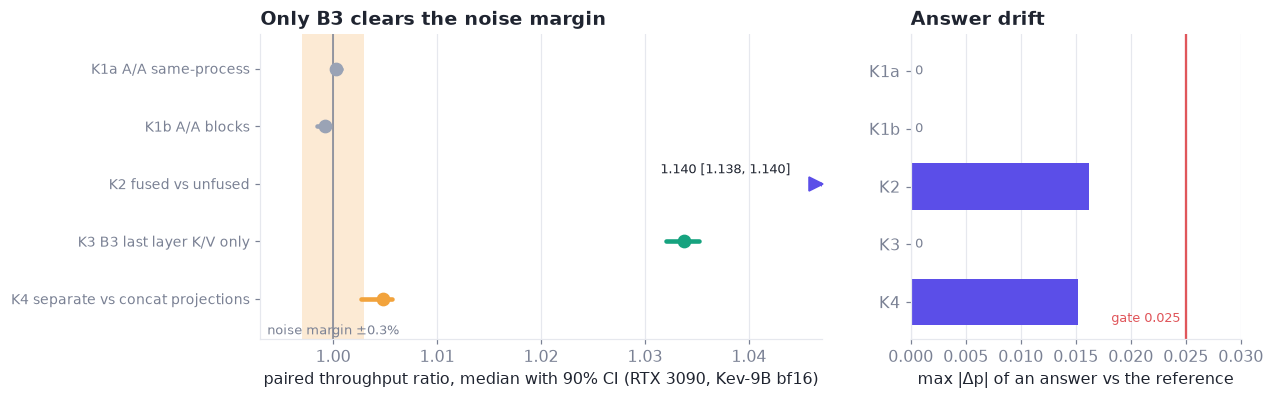

In [2]:
d = meas[meas.label.isin(["K2", "K3", "K4"])]
col = {"adopt": C["good"], "no effect": C["accent"], "baseline (reference drift)": C["ours"]}
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.7, 1]})
a.axvspan(0.997, 1.003, color=C["accent"], alpha=0.22, lw=0); a.axvline(1, color=MUTED, lw=1)
rows = list(aa.itertuples()) + list(d.itertuples())
for i, r in enumerate(rows):
    y = len(rows) - 1 - i; c = C["ref"] if r.label.startswith("K1") else col.get(r.decision, C["ref"])
    a.plot([max(r.ci90_lo, 0.993), min(r.ci90_hi, 1.047)], [y, y], color=c, lw=3, solid_capstyle="round")
    if r.median_ratio < 1.047: a.plot(r.median_ratio, y, "o", color=c, ms=8)
    else:
        a.plot(1.0465, y, ">", color=c, ms=9, clip_on=False)
        a.text(1.044, y + 0.18, f"{r.median_ratio:.3f} [{r.ci90_lo:.3f}, {r.ci90_hi:.3f}]", ha="right", fontsize=8.5, color=INK)
a.set_yticks(range(len(rows)), [f"{r.label} {r.change.split(' (')[0]}" for r in rows][::-1], fontsize=9)
a.set_xlim(0.993, 1.047); a.set_xlabel("paired throughput ratio, median with 90% CI (RTX 3090, Kev-9B bf16)"); a.grid(axis="y", visible=False)
a.set_title("Only B3 clears the noise margin")
a.set_ylim(-0.7, len(rows) - 0.4); a.text(1.0, -0.62, "noise margin ±0.3%", ha="center", fontsize=8.5, color=MUTED)
g = runs[runs.dp_max.notna()]
b.barh(g.label[::-1], g.dp_max[::-1], color=C["ours"]); b.axvline(0.025, color=C["bad"], lw=1.5)
b.text(0.0245, -0.4, "gate 0.025", ha="right", va="bottom", fontsize=8.5, color=C["bad"]); b.set_xlim(0, 0.03)
[b.text(0.0004, k, "0", va="center", fontsize=8.5, color=MUTED) for k, v in enumerate(g.dp_max[::-1]) if v == 0]
b.set_xlabel("max |Δp| of an answer vs the reference"); b.set_title("Answer drift"); b.grid(axis="y", visible=False)
save(fig, "kev_prefill_ratios"); plt.show()

## Where the time goes

Left: the share of a request spent in the state pass (one long forward) and in the question rows. Right: CUDA time by
kernel category inside the state pass. At 28k tokens, GEMM is 81% of the state pass, and its largest GEMM (gate and
up projection) runs at about 95% of the 3090's bf16 peak, so there is nothing to tune there.

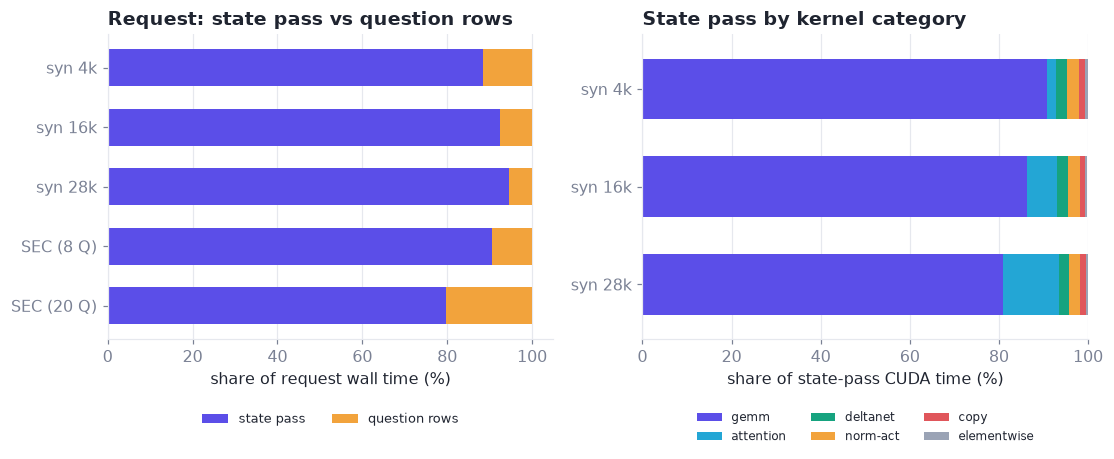

In [3]:
P = pd.read_csv(DATA / "kev_prefill_profile.csv")
sp = P[P.kind == "split"].pivot_table(index="workload", columns="item", values="share_pct", sort=False)
ct = P[(P.kind == "category") & (P.phase == "state_pass")].pivot_table(index="workload", columns="item", values="share_pct", sort=False)
ct = ct[["gemm", "attention", "deltanet", "norm-act", "copy", "elementwise"]]
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.6))
sp[["state", "rows"]].plot.barh(stacked=True, ax=a, color=[C["ours"], C["accent"]], width=0.62); a.invert_yaxis()
a.set_xlabel("share of request wall time (%)"); a.set_ylabel(""); a.set_title("Request: state pass vs question rows"); a.grid(axis="y", visible=False)
a.legend(["state pass", "question rows"], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=8.5)
ct.plot.barh(stacked=True, ax=b, color=[C["ours"], C["cyan"], C["good"], C["accent"], C["bad"], C["ref"]], width=0.62); b.invert_yaxis()
b.set_xlim(0, 100); b.set_xlabel("share of state-pass CUDA time (%)"); b.set_ylabel(""); b.set_title("State pass by kernel category")
b.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2)); b.grid(axis="y", visible=False)
save(fig, "kev_prefill_split"); plt.show()

Read every interval as a bound on this bench: 16 pairs come from 8 requests, so the bootstrap resamples requests (clusters), not single ratios. [Writeup](../docs/writeups/WRITEUP_SM86_SM89.md) · [Kernel kits](../kernels/README.md).

[Notebook guide](README.md) · [Documentation](../docs/README.md#reading-order) · [Data provenance](../data/README.md)